<a href="https://colab.research.google.com/github/tusharguleria542/Statistics-Practical/blob/main/Practical10_by_TushArGuleria(GF202459441).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Practical 10
Please work on wine dataset:
1. Display the Basic Statistics using describe ()
2. Boxplot by output labels/classes
3. Scatterplot using two variable
4. Plot Co-Variance Matrix
5. Data Scaling
6. Show better class separation using principal components

# **Importing libraries and dataset** :

Imports: Brings in tools for data tables (pandas), math (numpy), graphing (matplotlib, seaborn), and grabs a built-in practice dataset (sklearn).

load_wine(): Downloads the raw data about different wines (like alcohol content, color, etc.).

pd.DataFrame(...): Takes that raw data and its column names and turns it into a neat, readable table (like a spreadsheet).

df['target']: Adds a new column at the end of the table acting as an "answer key." It tags each row with a 0, 1, or 2 to show which of the three types of wine it is.

df.head(): Shows you the first 5 rows of your new table so you can quickly check if everything looks right.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine

wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['target'] = wine.target   # class labels: 0, 1, 2

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


# 1. Basic statistics with describe()

df.describe(): Instantly calculates and displays a statistical summary for every column in your table. It gives you a quick overview of your data by showing the total count, average (mean), minimum, maximum, standard deviation, and percentiles (how the data is spread out) for all your wine measurements at a glance.

In [ ]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


# 2. Boxplot by class

It draws one box per class (0, 1, 2) for the alcohol feature, so you can see how its spread differs between classes

plt.figure(figsize=(8,5)): Sets up the blank canvas for your chart, making it 8 inches wide and 5 inches tall.

sns.boxplot(...): Draws a boxplot (a type of chart that shows the average, spread, and outliers of data). It places the three wine types (target) on the bottom x-axis and their alcohol levels on the vertical y-axis so you can easily compare them side-by-side.

plt.title(...): Adds the title "Alcohol by Wine Class" to the top of your chart.

plt.show(): Actually renders and displays the finished chart on your screen.

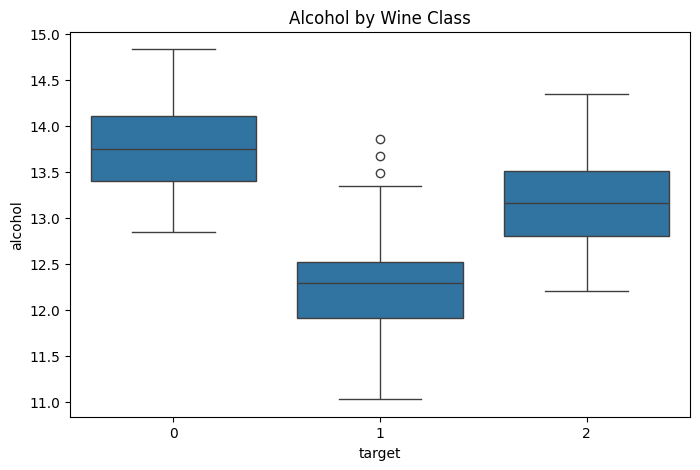

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x='target', y='alcohol', data=df)
plt.title('Alcohol by Wine Class')
plt.show()

# **3. Scatterplot using two variables**

plt.figure(figsize=(8,6)): Sets up the blank canvas for your chart, making it 8 inches wide and 6 inches tall.

sns.scatterplot(...): Draws a scatter plot (a graph made of dots). It places alcohol on the bottom x-axis and flavanoids on the vertical y-axis.

hue='target' colors each dot based on its wine type (0, 1, or 2) so you can tell them apart.

palette='Set1' tells the chart to use a specific set of distinct colors (like red, blue, and green) for those dots.

plt.title(...): Adds the title "Alcohol vs Flavanoids" to the top of the chart.

plt.show(): Renders and displays the finished graph on your screen.

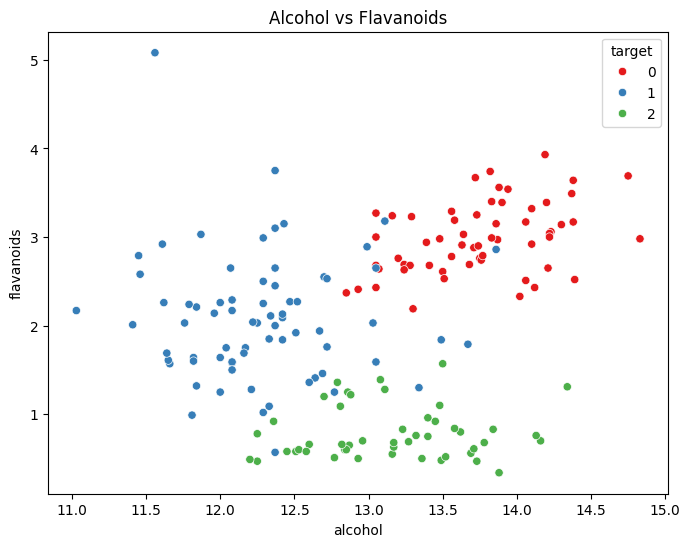

In [ ]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='alcohol', y='flavanoids', hue='target', palette='Set1', data=df)
plt.title('Alcohol vs Flavanoids')
plt.show()

# **4. Covariance matrix**

cov_matrix = ...: First, it temporarily removes the target column (since it's just category labels, not a measurement) and then calculates the "covariance." This is the math that figures out how much the different wine features (like alcohol, color, etc.) increase or decrease together.

plt.figure(figsize=(12,9)): Sets up a large 12-inch wide by 9-inch tall blank canvas.

sns.heatmap(...): Creates a color-coded grid (a heatmap) to visualize those math results.

annot=True writes the actual numbers inside the boxes.

fmt='.1f' rounds those numbers to one decimal place to keep it clean.

cmap='coolwarm' uses a blue-to-red color scheme (e.g., red for features that go up together, blue for the opposite).

plt.title(...): Adds the title "Covariance Matrix" to the top of your chart.

plt.show(): Renders and displays the finished grid on your screen.

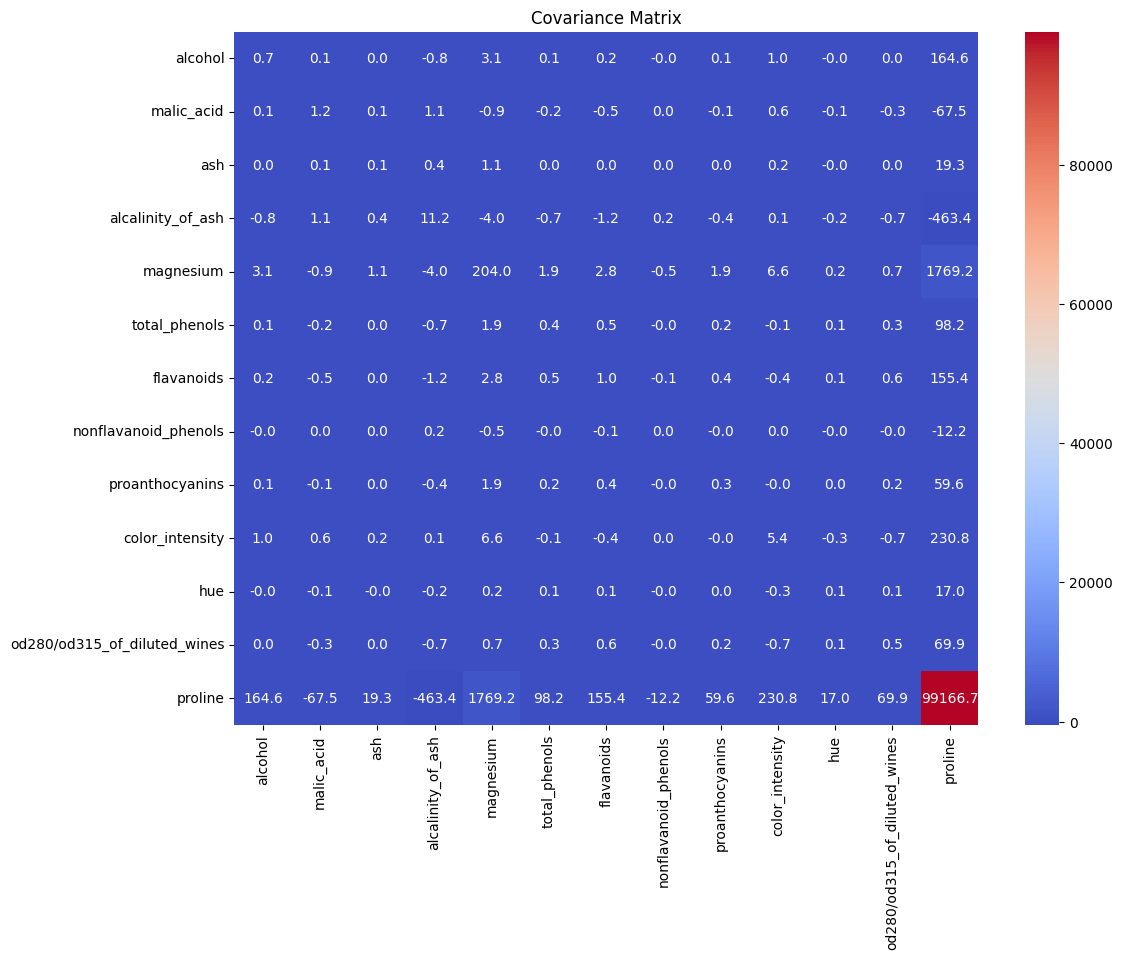

In [ ]:
cov_matrix = df.drop('target', axis=1).cov()

plt.figure(figsize=(12,9))
sns.heatmap(cov_matrix, annot=True, fmt='.1f', cmap='coolwarm')
plt.title('Covariance Matrix')
plt.show()

# **5. Data scaling**

from sklearn.preprocessing import StandardScaler: Brings in a tool that normalizes your data (shrinks or stretches the numbers so they are all on the same scale, like measuring everything in inches instead of mixing miles and millimeters).

X = df.drop('target', axis=1) and y = df['target']: Splits the table into two parts: X holds only the wine measurements (features), and y holds only the answers/labels (the wine types).

scaler = StandardScaler(): Gets the scaling tool ready to use.

X_scaled = scaler.fit_transform(X): Does the actual math. It looks at the data (fit) to find the averages, and then updates all the numbers (transform) so every column has an average of 0 and a similar spread.

X_scaled_df = pd.DataFrame(...): Takes those newly scaled numbers (which are just a raw list right now) and puts them back into a nice, readable table with the original column headers.

X_scaled_df.describe().round(2): Shows a quick statistical summary of your new table (like minimum, maximum, and average values) and rounds the numbers to 2 decimal places to make it easy to read. You'll notice the mean for every column is now exactly 0

In [ ]:
from sklearn.preprocessing import StandardScaler

X = df.drop('target', axis=1)
y = df['target']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled_df.describe().round(2)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.43,-1.43,-3.68,-2.67,-2.09,-2.11,-1.70,-1.87,-2.07,-1.63,-2.09,-1.90,-1.49
25%,-0.79,-0.66,-0.57,-0.69,-0.82,-0.89,-0.83,-0.74,-0.60,-0.80,-0.77,-0.95,-0.78
50%,0.06,-0.42,-0.02,0.00,-0.12,0.10,0.11,-0.18,-0.06,-0.16,0.03,0.24,-0.23
75%,0.84,0.67,0.70,0.60,0.51,0.81,0.85,0.61,0.63,0.49,0.71,0.79,0.76
max,2.26,3.11,3.16,3.15,4.37,2.54,3.06,2.40,3.49,3.44,3.30,1.96,2.97


# **6. Better class separation using PCA**

from sklearn.decomposition import PCA: Brings in a tool called PCA (Principal Component Analysis). Its job is to simplify complex data by combining many columns into just a few, while keeping as much important information as possible.

pca = PCA(n_components=2): Sets up the tool to squash all 13 of the wine measurements down into just 2 new "super columns" (so we can easily plot it on a 2D graph).

X_pca = pca.fit_transform(X_scaled): Does the actual math on your scaled data to create those 2 new columns.

pca_df = pd.DataFrame(...) and pca_df['target'] = y: Puts these 2 new columns into a neat table (naming them 'PC1' and 'PC2') and attaches the wine types (0, 1, or 2) back onto the end so we know which row is which.

plt.figure(...) to plt.show(): Draws a scatter plot of your 2 new columns. It colors the dots by wine type (hue='target') so you can visually see how well PCA separated the three different wines into distinct clusters.

print("Variance explained: ..."): Prints out a percentage showing exactly how much of the original data's "story" or information was successfully captured by squeezing it down to just 2 columns.


PCA squeezes the 13 features into 2 new "principal components" that keep the most information. Plotting them with class colors shows the 3 wine classes forming clearly separated groups, much cleaner than the scatterplot in step 3. The last line tells you how much of the total variance each component captures (roughly 36% and 19%).

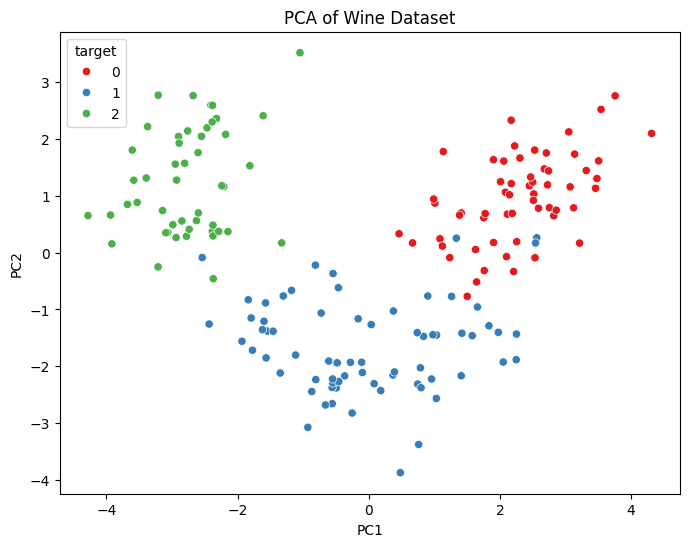

Variance explained: [0.36198848 0.1920749 ]


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['target'] = y

plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', hue='target', palette='Set1', data=pca_df)
plt.title('PCA of Wine Dataset')
plt.show()

print("Variance explained:", pca.explained_variance_ratio_)